# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Adversarial and Stochastic Search

## Minimax

* **Purpose:** Choose a move against an opponent who also plays optimally in a deterministic, two-player, zero-sum game.
* **Main idea:** MAX chooses the largest child value; MIN chooses the smallest. Values propagate from the leaves toward the root.
* **Recursive rule:**
$$V(n)=\begin{cases}U(n),&n\text{ is terminal},\\\max_{c\in C(n)}V(c),&n\text{ is MAX},\\\min_{c\in C(n)}V(c),&n\text{ is MIN}.\end{cases}$$
* The root is MAX. Its children are MIN, their children are MAX, and so on.

$$
\begin{array}{l}
\hline
\textbf{Algorithm: Minimax}\\
\hline
\textbf{Input: }\text{Node }n,\text{ Boolean }is\_max=\mathrm{True},\text{ optional counter }stats=\mathrm{None}\\
\textbf{Output: }\text{Minimax value of }n\\[4pt]
1.\quad \textbf{if }n\text{ is not a list }\textbf{then}\\
2.\quad \qquad \textbf{if }stats\neq\mathrm{None}\textbf{ then}\\
3.\quad \qquad\qquad stats[\text{“leaves”}]\gets stats[\text{“leaves”}]+1\\
4.\quad \qquad \textbf{end if}\\
5.\quad \qquad \textbf{return }n\\
6.\quad \textbf{end if}\\
7.\quad values\gets[\,]\\
8.\quad \textbf{for each }\text{child }c\text{ in }n\textbf{ do}\\
9.\quad \qquad values.\mathrm{append}\bigl(\mathrm{Minimax}(c,\neg is\_max,stats)\bigr)\\
10.\quad \textbf{end for}\\
11.\quad \textbf{if }is\_max=\mathrm{True}\textbf{ then}\\
12.\quad \qquad \textbf{return }\max(values)\\
13.\quad \textbf{else}\\
14.\quad \qquad \textbf{return }\min(values)\\
15.\quad \textbf{end if}\\
\hline
\end{array}
$$

**Minimax on the first supplied tree.**

* Each inner list represents one MIN node. Its numbers are terminal utilities.
* `is_max` switches the player at each recursive call. `stats` counts evaluated leaves.

MIN branch values: [3, 2, 2]
Minimax value: 3
Best branch: A
Evaluated leaves: 9


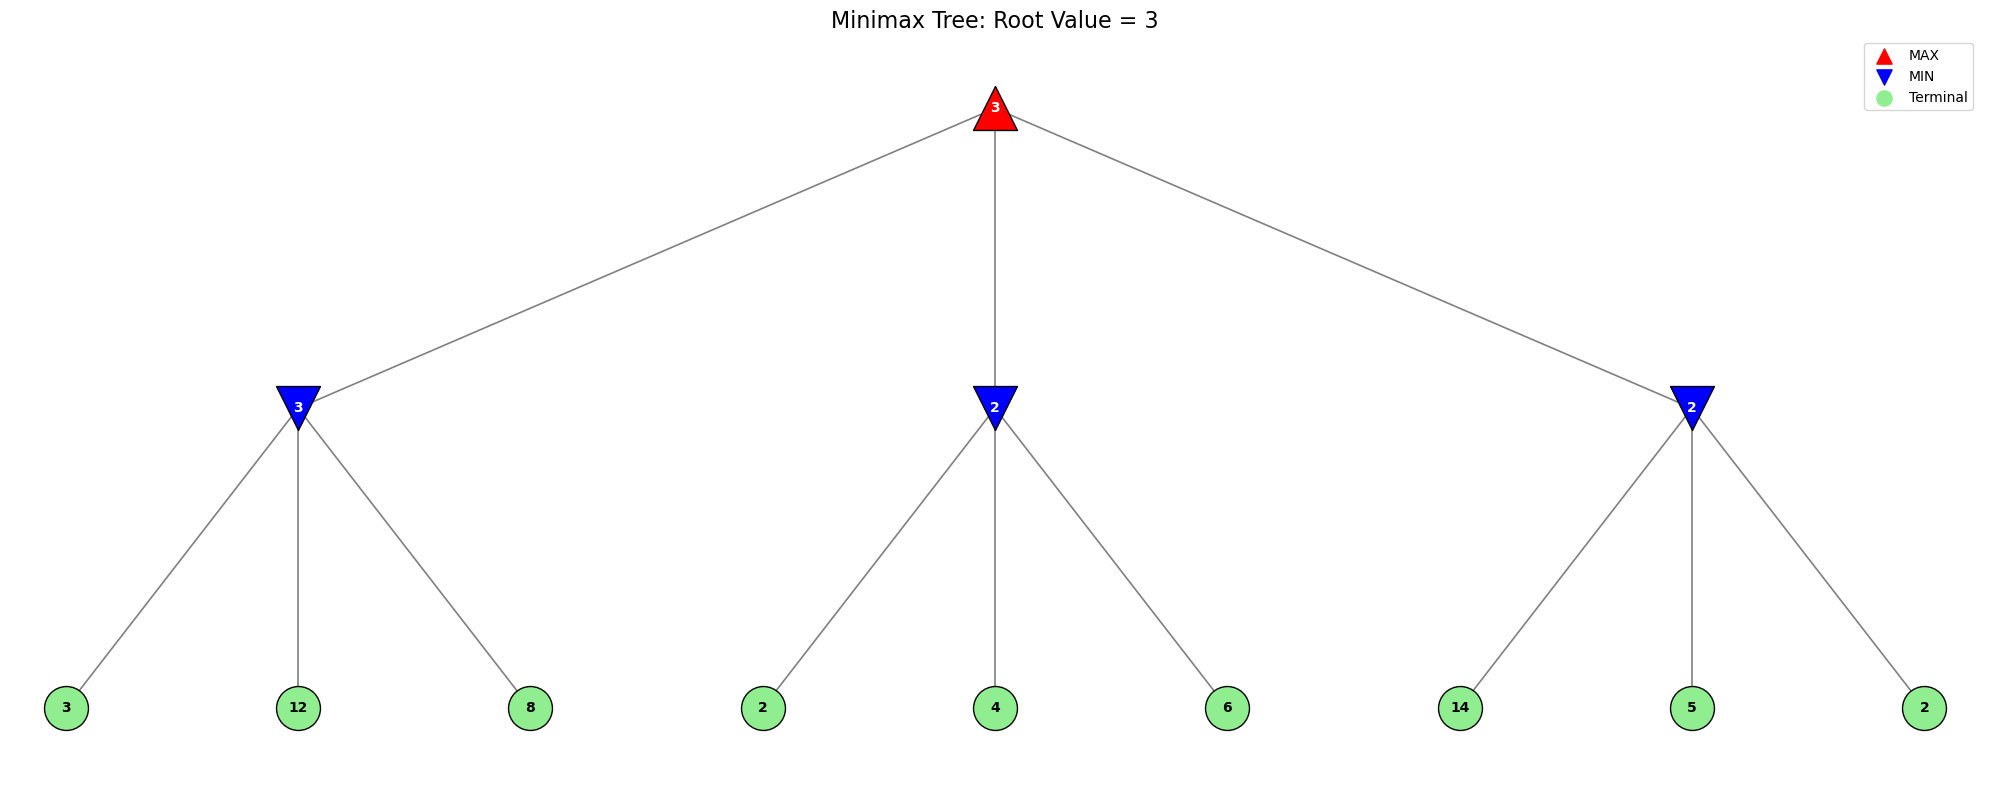

In [ ]:
import matplotlib.pyplot as plt

#tree = [[3, 5], [2, 9]]
#tree = [[5, 9, 1], [4, 6, 7], [3, 8, 2]]
tree = [[3, 12, 8], [2, 4, 6], [14, 5, 2]]
#tree = [[3, 12, 8, 2], [2, 4, 6, 1], [14, 5, 2, 3]]


def minimax(node, is_max=True, stats=None):
    if not isinstance(node, list):
        if stats is not None:
            stats["leaves"] += 1 #count the number of leaves evaluated
        return node
    values = [minimax(child, not is_max, stats) for child in node]
    return max(values) if is_max else min(values)

stats = {"leaves": 0}
branch_values = [minimax(branch, False) for branch in tree]
value = minimax(tree, stats=stats)
move = branch_values.index(value)

print("MIN branch values:", branch_values)
print("Minimax value:", value)
print("Best branch:", "ABC"[move])
print("Evaluated leaves:", stats["leaves"])

fig, ax = plt.subplots(figsize=(20, 8))
leaf_position = [0]

def plot_tree(node, depth=0):
    if not isinstance(node, list):
        x = leaf_position[0]
        leaf_position[0] += 1
        value, marker, color = node, "o", "lightgreen"
    else:
        children = [plot_tree(child, depth + 1) for child in node]
        x = sum(child[0] for child in children) / len(children)
        is_max = depth % 2 == 0
        values = [child[1] for child in children]
        value = max(values) if is_max else min(values)
        marker, color = ("^", "red") if is_max else ("v", "blue")

        for child_x, _ in children:
            ax.plot([x, child_x], [-depth, -depth - 1],
                    color="gray", linewidth=1.2, zorder=1)

    ax.scatter(x, -depth, marker=marker, s=1000,
               color=color, edgecolor="black", zorder=2)
    ax.text(x, -depth, str(value), ha="center", va="center",
            color="black" if marker == "o" else "white",
            fontsize=10, fontweight="bold", zorder=3)
    return x, value

_, root_value = plot_tree(tree)

ax.scatter([], [], marker="^", color="red", s=120, label="MAX")
ax.scatter([], [], marker="v", color="blue", s=120, label="MIN")
ax.scatter([], [], marker="o", color="lightgreen", s=120, label="Terminal")

ax.set_title(f"Minimax Tree: Root Value = {root_value}", fontsize=16)
ax.legend(loc="upper right")
ax.margins(x=0.03, y=0.12)
ax.axis("off")
plt.tight_layout()

- **Tree:** Each inner list represents a MIN branch, and each number represents a terminal utility.
- **Recursive evaluation:** `minimax()` alternates between MAX and MIN. MAX chooses the largest child value; MIN chooses the smallest.
- **Terminal nodes:** When a number is reached, the function returns it and increments the leaf counter if `stats` is provided.
- **Branch values:** A returns $\min(3,12,8)=3$, B returns $\min(2,4,6)=2$, and C returns $\min(14,5,2)=2$.
- **Best move:** The MAX root chooses $\max(3,2,2)=3$, so the best branch is **A**.
- **Leaf count:** The counted root search evaluates all **9 terminal leaves**. There is no pruning.
- **Tree layout:** `plot_tree()` places leaves from left to right and centers each parent above its children.
- **Node appearance:** MAX nodes are red upward triangles, MIN nodes are blue downward triangles, and terminal nodes are green circles.
- **Visualization:** Gray edges connect parents to children, and each node displays its computed value.

## Minimax Pruning

* **Purpose:** Skip subtrees that cannot change the root decision.
* Pruning is an improvement to minimax. Alpha-beta pruning is the standard general method, rather than a separate decision rule.
* This first demonstration uses a two-level MAX-to-MIN tree. Once a MIN branch finds a value no greater than MAX's best completed branch, MAX cannot prefer that branch strictly.
* The remaining leaves in that branch may be skipped. Its returned partial value is an upper bound on its true MIN value.

**A simple cutoff before the general recursive algorithm.**

* `best` is the largest completed branch value so far.
* A cutoff occurs only when at least one unvisited leaf remains. Counts refer to terminal leaves, not cutoff events.

$$
\begin{array}{l}
\hline
\textbf{Algorithm: Simple Cutoff Minimax Pruning}\\
\hline
\textbf{Input: }\text{Branches of a MAX root, each containing terminal leaves of a MIN node}\\
\textbf{Output: }best,\ best\_move,\ visited,\ skipped,\ branch\_labels\\[4pt]
1.\quad best\gets-\infty,\quad best\_move\gets\mathrm{None}\\
2.\quad visited\gets[\,],\quad skipped\gets[\,],\quad branch\_labels\gets[\,]\\
3.\quad \textbf{for each }\text{branch }i\text{ from left to right }\textbf{do}\\
4.\quad \qquad current\gets+\infty,\quad pruned\gets\mathrm{False}\\
5.\quad \qquad \textbf{for each }\text{leaf }j\text{ in branch }i\text{ from left to right }\textbf{do}\\
6.\quad \qquad\qquad visited.\mathrm{append}((i,j))\\
7.\quad \qquad\qquad current\gets\min(current,branches[i][j])\\
8.\quad \qquad\qquad \textbf{if }current\leq best\text{ and unvisited leaves remain }\textbf{then}\\
9.\quad \qquad\qquad\qquad \text{Append all remaining leaf positions }(i,k)\text{ to }skipped\\
10.\quad \qquad\qquad\qquad pruned\gets\mathrm{True}\\
11.\quad \qquad\qquad\qquad \textbf{break}\\
12.\quad \qquad\qquad \textbf{end if}\\
13.\quad \qquad \textbf{end for}\\
14.\quad \qquad \textbf{if }pruned\textbf{ then}\\
15.\quad \qquad\qquad branch\_labels.\mathrm{append}(\text{“}\leq current\text{”})\\
16.\quad \qquad \textbf{else}\\
17.\quad \qquad\qquad branch\_labels.\mathrm{append}(\mathrm{str}(current))\\
18.\quad \qquad\qquad \textbf{if }current>best\textbf{ then}\\
19.\quad \qquad\qquad\qquad best\gets current,\quad best\_move\gets i\\
20.\quad \qquad\qquad \textbf{end if}\\
21.\quad \qquad \textbf{end if}\\
22.\quad \textbf{end for}\\
23.\quad \textbf{return }best,\ best\_move,\ visited,\ skipped,\ branch\_labels\\
\hline
\end{array}
$$

Minimax value: 4
Best branch: B
Evaluated leaf values: [5, 9, 1, 4, 6, 7, 3]
Pruned leaf values: [8, 2]
Evaluated terminal leaves: 7
Pruned terminal leaves: 2


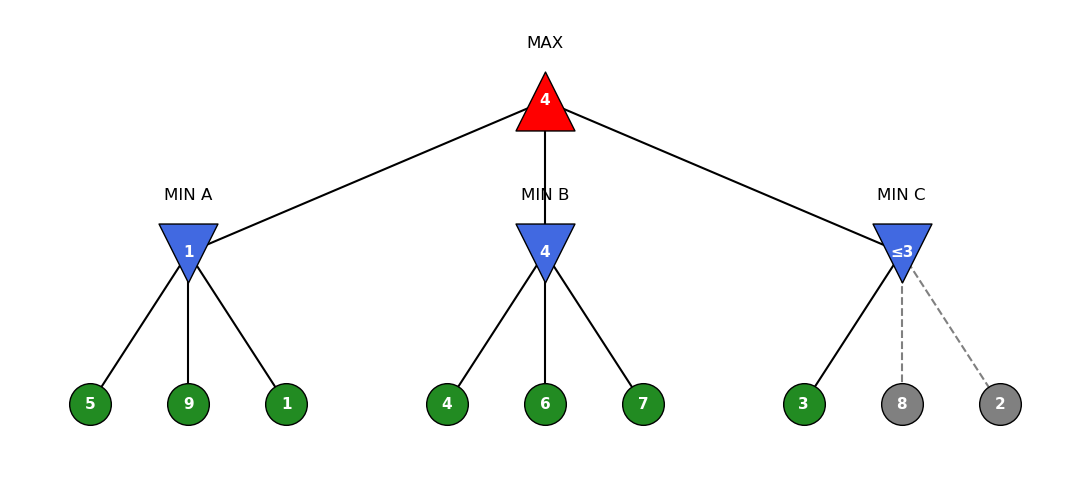

In [ ]:
import matplotlib.pyplot as plt

tree = [[5, 9, 1], [4, 6, 7], [3, 8, 2]]

def minimax_pruning(branches):
    best, best_move = float("-inf"), None
    visited, skipped, branch_labels = [], [], []

    for i, branch in enumerate(branches):
        current = float("inf")
        pruned = False

        for j, leaf in enumerate(branch):
            visited.append((i, j))
            current = min(current, leaf)

            # Cut off only if unvisited terminal leaves remain.
            if current <= best and j + 1 < len(branch):
                skipped.extend((i, k) for k in range(j + 1, len(branch)))
                pruned = True
                break

        branch_labels.append(f"≤{current}" if pruned else str(current))

        # Update best only after evaluating a complete branch.
        if not pruned and current > best:
            best, best_move = current, i

    return best, best_move, visited, skipped, branch_labels

def draw_tree(tree, branch_labels, value, skipped):
    fig, ax = plt.subplots(figsize=(11, 5))
    skipped = set(skipped)
    branch_x = [(i - (len(tree) - 1) / 2) * 4
                for i in range(len(tree))]

    def node(x, y, label, marker, color, size):
        ax.scatter(x, y, marker=marker, s=size, color=color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, str(label), ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

    # MAX: red upward triangle
    node(0, 2, value, "^", "red", 1800)
    ax.text(0, 2.35, "MAX", ha="center", fontsize=12)

    for i, (x, branch) in enumerate(zip(branch_x, tree)):
        ax.plot([0, x], [2, 1], color="black", zorder=1)

        # MIN: blue downward triangle
        node(x, 1, branch_labels[i], "v", "royalblue", 1800)
        ax.text(x, 1.35, f"MIN {'ABC'[i]}", ha="center", fontsize=12)

        for j, leaf in enumerate(branch):
            leaf_x = x + (j - (len(branch) - 1) / 2) * 1.1
            pruned = (i, j) in skipped

            ax.plot([x, leaf_x], [1, 0],
                    color="gray" if pruned else "black",
                    linestyle="--" if pruned else "-",
                    linewidth=1.5, zorder=1)

            # Terminal leaves: green circles; pruned leaves: gray circles
            node(leaf_x, 0, leaf, "o",
                 "gray" if pruned else "forestgreen", 900)

    ax.set_ylim(-0.5, 2.6)
    ax.set_xlim(min(branch_x) - 2, max(branch_x) + 2)
    ax.axis("off")
    plt.tight_layout()

value, move, visited, skipped, labels = minimax_pruning(tree)

print("Minimax value:", value)
print("Best branch:", "ABC"[move])
print("Evaluated leaf values:", [tree[i][j] for i, j in visited])
print("Pruned leaf values:", [tree[i][j] for i, j in skipped])
print("Evaluated terminal leaves:", len(visited))
print("Pruned terminal leaves:", len(skipped))

draw_tree(tree, labels, value, skipped)

- **Tree:** The root is MAX, each branch is MIN, and the numbers are terminal utilities.
- **Best value:** `best` stores the largest fully evaluated branch value so far. It starts at $-\infty$.
- **Branch evaluation:** `current` tracks the smallest visited leaf value in each MIN branch.
- **Branch A:** All leaves `[5, 9, 1]` are visited. A returns **1**, so `best = 1`.
- **Branch B:** All leaves `[4, 6, 7]` are visited. B returns **4**, so `best = 4`.
- **Branch C:** Its first leaf is **3**. Since $3 \leq 4$, C cannot improve the root’s choice. The remaining leaves **8 and 2** are pruned.
- **Cutoff condition:** Pruning occurs when `current <= best` and at least one unvisited leaf remains.
- **Branch labels:** Completed branches display their exact values. C displays **≤3**, an upper bound rather than its exact value.
- **Final result:** The minimax value is **4**, and the best branch is **B**. The algorithm evaluates **7 terminal leaves** and prunes **2**.
- **Visualization:** MAX is a red upward triangle, MIN nodes are blue downward triangles, and evaluated leaves are green circles. Pruned leaves are gray circles with gray dashed edges.

Minimax value: 3
Best branch: A
Evaluated leaf values: [5, 9, 3, 1, 1]
Pruned leaf values: [6, 7, 8, 2]
Evaluated terminal leaves: 5
Pruned terminal leaves: 4


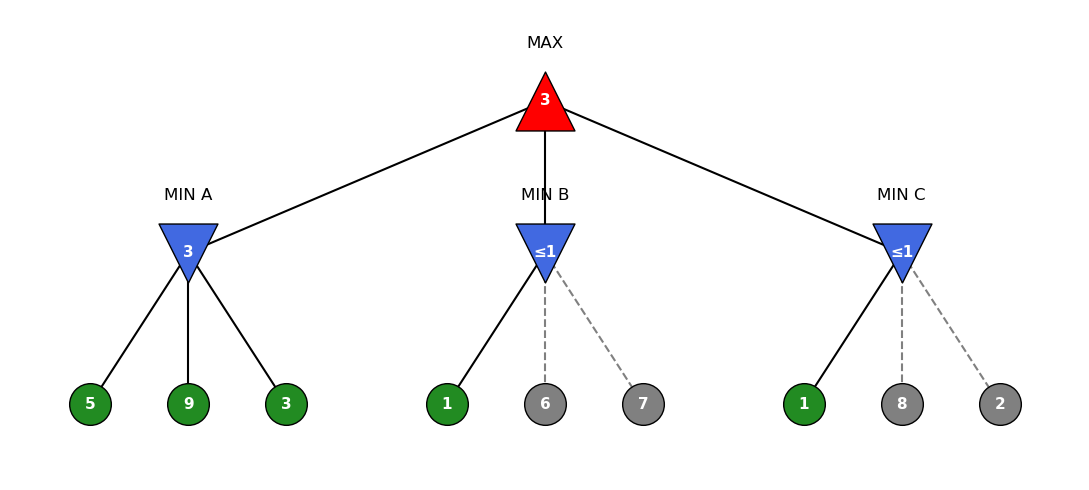

In [ ]:
import matplotlib.pyplot as plt

tree = [[5, 9, 3], [1, 6, 7], [1, 8, 2]]

def minimax_pruning(branches):
    best, best_move = float("-inf"), None
    visited, skipped, branch_labels = [], [], []

    for i, branch in enumerate(branches):
        current = float("inf")
        pruned = False

        for j, leaf in enumerate(branch):
            visited.append((i, j))
            current = min(current, leaf)

            # Cut off only if unvisited terminal leaves remain.
            if current <= best and j + 1 < len(branch):
                skipped.extend((i, k) for k in range(j + 1, len(branch)))
                pruned = True
                break

        branch_labels.append(f"≤{current}" if pruned else str(current))

        # Update best only after evaluating a complete branch.
        if not pruned and current > best:
            best, best_move = current, i

    return best, best_move, visited, skipped, branch_labels

def draw_tree(tree, branch_labels, value, skipped):
    fig, ax = plt.subplots(figsize=(11, 5))
    skipped = set(skipped)
    branch_x = [(i - (len(tree) - 1) / 2) * 4
                for i in range(len(tree))]

    def node(x, y, label, marker, color, size):
        ax.scatter(x, y, marker=marker, s=size, color=color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, str(label), ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

    # MAX: red upward triangle
    node(0, 2, value, "^", "red", 1800)
    ax.text(0, 2.35, "MAX", ha="center", fontsize=12)

    for i, (x, branch) in enumerate(zip(branch_x, tree)):
        ax.plot([0, x], [2, 1], color="black", zorder=1)

        # MIN: blue downward triangle
        node(x, 1, branch_labels[i], "v", "royalblue", 1800)
        ax.text(x, 1.35, f"MIN {'ABC'[i]}", ha="center", fontsize=12)

        for j, leaf in enumerate(branch):
            leaf_x = x + (j - (len(branch) - 1) / 2) * 1.1
            pruned = (i, j) in skipped

            ax.plot([x, leaf_x], [1, 0],
                    color="gray" if pruned else "black",
                    linestyle="--" if pruned else "-",
                    linewidth=1.5, zorder=1)

            # Terminal leaves: green circles; pruned leaves: gray circles
            node(leaf_x, 0, leaf, "o",
                 "gray" if pruned else "forestgreen", 900)

    ax.set_ylim(-0.5, 2.6)
    ax.set_xlim(min(branch_x) - 2, max(branch_x) + 2)
    ax.axis("off")
    plt.tight_layout()

value, move, visited, skipped, labels = minimax_pruning(tree)

print("Minimax value:", value)
print("Best branch:", "ABC"[move])
print("Evaluated leaf values:", [tree[i][j] for i, j in visited])
print("Pruned leaf values:", [tree[i][j] for i, j in skipped])
print("Evaluated terminal leaves:", len(visited))
print("Pruned terminal leaves:", len(skipped))

draw_tree(tree, labels, value, skipped)

- **Tree:** The root is MAX, each branch is MIN, and the numbers are terminal utilities.
- **Best value:** `best` stores the largest fully evaluated branch value so far. It starts at $-\infty$.
- **Branch evaluation:** `current` tracks the smallest visited leaf value in each MIN branch.
- **Branch A:** All leaves `[5, 9, 3]` are visited. A returns **3**, so `best = 3`.
- **Branch B:** Its first leaf is **1**. Since $1 \leq 3$, B cannot improve the root’s choice. The remaining leaves **6 and 7** are pruned.
- **Branch C:** Its first leaf is also **1**. Since $1 \leq 3$, the remaining leaves **8 and 2** are pruned.
- **Cutoff condition:** Pruning occurs when `current <= best` and at least one unvisited leaf remains.
- **Branch labels:** A displays its exact value, **3**. B and C display **≤1**, because their remaining leaves were not evaluated.
- **Final result:** The minimax value is **3**, and the best branch is **A**. The algorithm evaluates **5 terminal leaves** and prunes **4**.
- **Visualization:** MAX is a red upward triangle, MIN nodes are blue downward triangles, and evaluated leaves are green circles. Pruned leaves are gray circles with gray dashed edges.

Minimax value: 6
Best branch: A
Evaluated leaf values: [5, 6, 7, 8, 4, 3]
Pruned leaf values: [9, 10]
Evaluated terminal leaves: 6
Pruned terminal leaves: 2


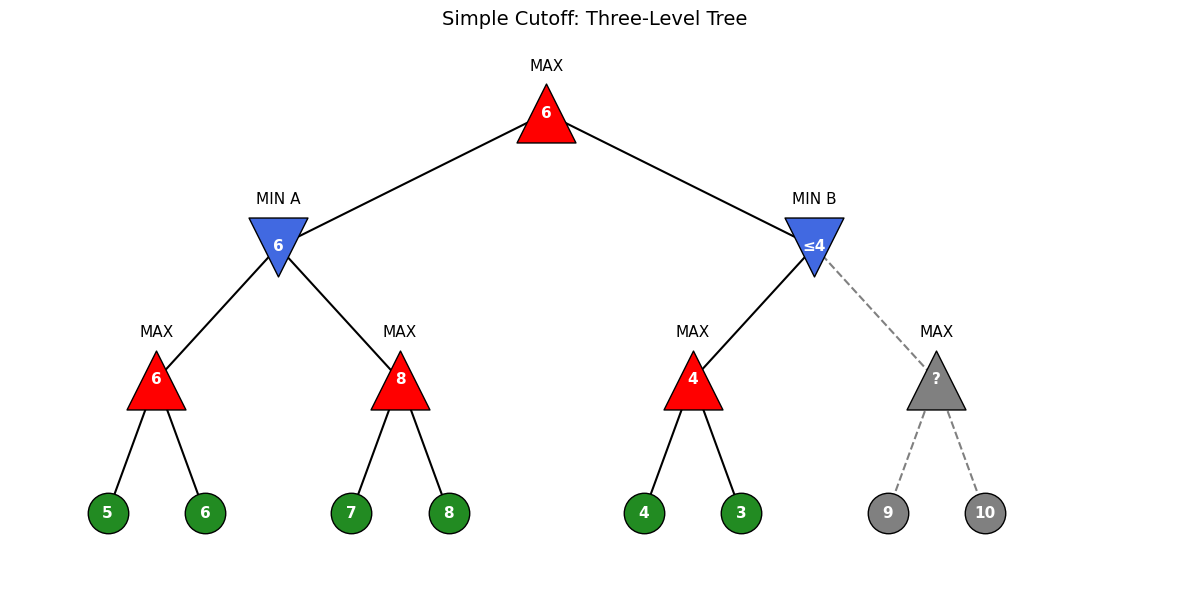

In [ ]:
#three-level tree

import matplotlib.pyplot as plt

# MAX → MIN → MAX → terminal leaves
tree = [
    [[5, 6], [7, 8]],
    [[4, 3], [9, 10]]
]

def simple_cutoff(tree):
    best, best_move = float("-inf"), None
    visited, skipped, labels = [], [], {}

    for i, branch in enumerate(tree):
        current = float("inf")
        complete = True

        for j, leaves in enumerate(branch):
            # Fully evaluate this MAX child.
            child_value = float("-inf")
            for k, leaf in enumerate(leaves):
                visited.append((i, j, k))
                child_value = max(child_value, leaf)

            labels[(i, j)] = str(child_value)
            current = min(current, child_value)

            # Skip remaining MAX children and their terminal leaves.
            if current <= best and j + 1 < len(branch):
                for remaining in range(j + 1, len(branch)):
                    skipped.extend(
                        (i, remaining, k)
                        for k in range(len(branch[remaining]))
                    )
                complete = False
                break

        labels[(i,)] = str(current) if complete else f"≤{current}"

        if complete and current > best:
            best, best_move = current, i

    labels[()] = str(best)
    return best, best_move, visited, skipped, labels


def draw_tree(tree, labels, skipped):
    skipped = set(skipped)
    positions = {}
    next_x = 0

    # Position leaves first, then center parents above their children.
    for i, branch in enumerate(tree):
        for j, leaves in enumerate(branch):
            for k in range(len(leaves)):
                positions[(i, j, k)] = (next_x, 0)
                next_x += 1
            positions[(i, j)] = (
                sum(positions[(i, j, k)][0]
                    for k in range(len(leaves))) / len(leaves), 1
            )
            next_x += 0.5

        positions[(i,)] = (
            sum(positions[(i, j)][0]
                for j in range(len(branch))) / len(branch), 2
        )
        next_x += 0.5

    positions[()] = (
        sum(positions[(i,)][0] for i in range(len(tree))) / len(tree), 3
    )

    pruned_nodes = set(skipped)
    for i, branch in enumerate(tree):
        for j, leaves in enumerate(branch):
            if all((i, j, k) in skipped for k in range(len(leaves))):
                pruned_nodes.add((i, j))

    fig, ax = plt.subplots(figsize=(12, 6))

    # Edges into pruned nodes are gray and dashed.
    for path, (x, y) in positions.items():
        if path:
            px, py = positions[path[:-1]]
            pruned = path in pruned_nodes
            ax.plot([px, x], [py, y],
                    color="gray" if pruned else "black",
                    linestyle="--" if pruned else "-",
                    linewidth=1.5, zorder=1)

    for path, (x, y) in positions.items():
        depth = len(path)
        pruned = path in pruned_nodes

        if depth == 3:
            marker, color, size = "o", "forestgreen", 850
            label = str(tree[path[0]][path[1]][path[2]])
        else:
            is_max = depth % 2 == 0
            marker = "^" if is_max else "v"
            color = "red" if is_max else "royalblue"
            size = 1800
            label = labels.get(path, "?")

        if pruned:
            color = "gray"

        ax.scatter(x, y, marker=marker, s=size, color=color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, label, ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

        if depth < 3:
            name = "MAX" if depth % 2 == 0 else f"MIN {'ABC'[path[0]]}"
            ax.text(x, y + 0.32, name, ha="center", fontsize=11)

    ax.set_ylim(-0.5, 3.6)
    ax.set_xlim(-1, next_x)
    ax.axis("off")
    ax.set_title("Simple Cutoff: Three-Level Tree", fontsize=14)
    plt.tight_layout()
    plt.show()


value, move, visited, skipped, labels = simple_cutoff(tree)

leaf_value = lambda p: tree[p[0]][p[1]][p[2]]

print("Minimax value:", value)
print("Best branch:", "ABC"[move])
print("Evaluated leaf values:", [leaf_value(p) for p in visited])
print("Pruned leaf values:", [leaf_value(p) for p in skipped])
print("Evaluated terminal leaves:", len(visited))
print("Pruned terminal leaves:", len(skipped))

draw_tree(tree, labels, skipped)

## Three-Level Simple Cutoff
- **Tree structure:** The levels are MAX → MIN → MAX → terminal leaves.
- **Best value:** `best` stores the largest fully evaluated MIN branch value so far. It starts at $-\infty$.
- **Lower MAX nodes:** Each lower MAX node visits all its leaves and returns the largest value.
- **Branch A:** `[5, 6]` returns **6**, and `[7, 8]` returns **8**. A is MIN, so it returns $\min(6,8)=6$. The root sets `best = 6`.
- **Branch B:** Its first MAX child, `[4, 3]`, returns **4**. B’s final MIN value can only be **4 or smaller**, so it cannot beat **6**.
- **Cutoff:** The entire remaining MAX subtree `[9, 10]` is skipped.
- **Branch labels:** A displays its exact value, **6**. B displays **≤4**, and its unevaluated MAX child displays **?**.
- **Final result:** The minimax value is **6**, and the best branch is **A**. The algorithm evaluates **6 terminal leaves** and prunes **2**.
- **Tree layout:** Leaves are placed from left to right, and parents are centered above their children.
- **Visualization:** MAX nodes are red upward triangles, MIN nodes are blue downward triangles, and evaluated leaves are green circles. Pruned nodes are gray with gray dashed edges.
- **Limitation:** This simple cutoff fully evaluates each lower MAX node. Unlike alpha–beta pruning, it does not skip **8**.

## Alpha-Beta Pruning

* **Purpose:** Apply minimax pruning recursively at any depth.
* **Alpha ($\alpha$):** The best lower bound already established for MAX along the current search path.
* **Beta ($\beta$):** The best upper bound already established for MIN along that path.
* MAX updates $\alpha$; MIN updates $\beta$. Stop exploring remaining children when $\alpha\geq\beta$.
* Initialize with $\alpha=-\infty$ and $\beta=+\infty$. Arbitrary finite initial bounds can cause incorrect cutoffs.
* This implementation uses local bounds and leaves the input tree unchanged.

$$
\begin{array}{l}
\hline
\textbf{Algorithm: Alpha-Beta Pruning}\\
\hline
\textbf{Input: }\text{Node }n,\text{ player }p\in\{\mathrm{MAX},\mathrm{MIN}\},
\text{ bounds }\alpha,\beta\\
\textbf{Output: }\text{Value }v\text{ (exact or a bound if pruning occurs)}\\
\textbf{Initial call: }\mathrm{AlphaBeta}(root,\mathrm{MAX},-\infty,+\infty)\\[4pt]
1.\quad \textbf{if }n\text{ is terminal }\textbf{then}\\
2.\quad \qquad \textbf{return }U(n)\\
3.\quad \textbf{end if}\\
4.\quad \textbf{if }p=\mathrm{MAX}\textbf{ then}\\
5.\quad \qquad v\gets-\infty\\
6.\quad \qquad \textbf{for each }\text{child }c\text{ of }n\textbf{ do}\\
7.\quad \qquad\qquad v\gets\max\bigl(v,\mathrm{AlphaBeta}(c,\mathrm{MIN},\alpha,\beta)\bigr)\\
8.\quad \qquad\qquad \alpha\gets\max(\alpha,v)\\
9.\quad \qquad\qquad \textbf{if }\alpha\geq\beta\textbf{ then}\\
10.\quad \qquad\qquad\qquad \textbf{break}\\
11.\quad \qquad\qquad \textbf{end if}\\
12.\quad \qquad \textbf{end for}\\
13.\quad \textbf{else}\\
14.\quad \qquad v\gets+\infty\\
15.\quad \qquad \textbf{for each }\text{child }c\text{ of }n\textbf{ do}\\
16.\quad \qquad\qquad v\gets\min\bigl(v,\mathrm{AlphaBeta}(c,\mathrm{MAX},\alpha,\beta)\bigr)\\
17.\quad \qquad\qquad \beta\gets\min(\beta,v)\\
18.\quad \qquad\qquad \textbf{if }\alpha\geq\beta\textbf{ then}\\
19.\quad \qquad\qquad\qquad \textbf{break}\\
20.\quad \qquad\qquad \textbf{end if}\\
21.\quad \qquad \textbf{end for}\\
22.\quad \textbf{end if}\\
23.\quad \textbf{return }v\\
\hline
\end{array}
$$

Minimax value: 8
Best branch: C
Evaluated leaf values: [4, 6, 7, 1, 2, 8, 1, 9]
Pruned leaf values: [9, 0, 1, 2]
Evaluated terminal leaves: 8
Pruned terminal leaves: 4


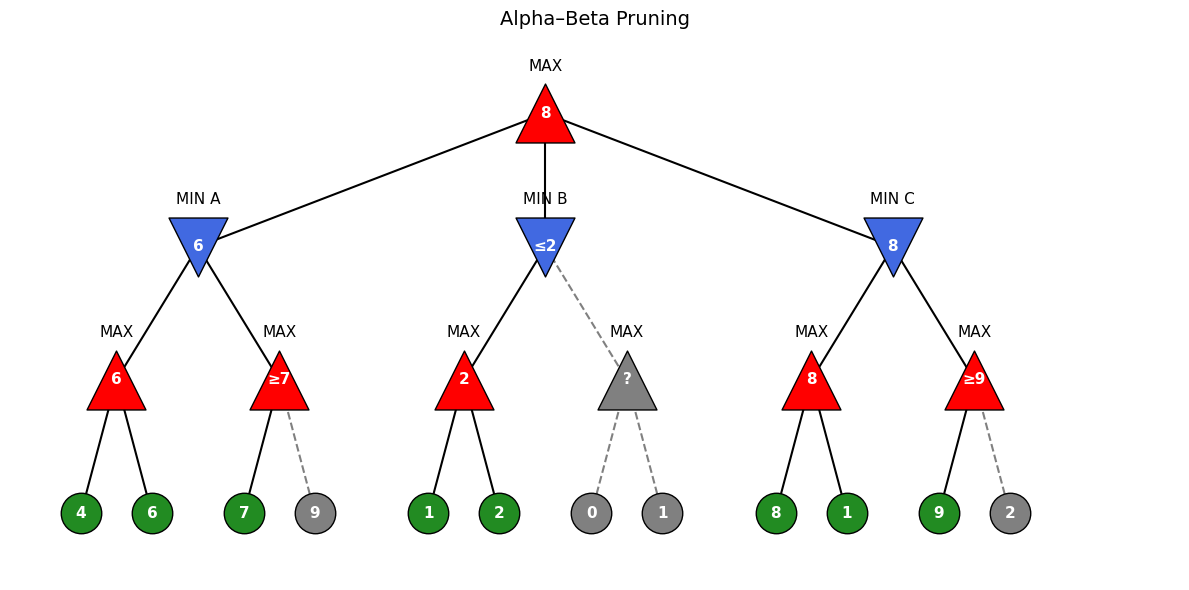

In [ ]:
import matplotlib.pyplot as plt

#tree = [[[5, 6], [7, 8]],[[4, 3], [9, 10]]]
#tree = [[[10, 6], [100, 8]],[[1, 2], [20, 4]]]
tree = [[[4, 6], [7, 9]],[[1, 2], [0, 1]], [[8, 1], [9, 2]]]
#tree = [[[6, 2, 6], [3, 9]], [[5, 2], [7, 3]]]
def alpha_beta(tree):
    visited, skipped, labels = [], [], {}

    def skip(node, path):
        if isinstance(node, list):
            for i, child in enumerate(node):
                skip(child, path + (i,))
        else:
            skipped.append(path)

    def search(node, alpha, beta, is_max, path=()):
        if not isinstance(node, list):
            visited.append(path)
            return node, None

        value = float("-inf") if is_max else float("inf")
        move, pruned = None, False

        for i, child in enumerate(node):
            child_value, _ = search(
                child, alpha, beta, not is_max, path + (i,)
            )

            if is_max:
                if child_value > value:
                    value, move = child_value, i
                alpha = max(alpha, value)
            else:
                if child_value < value:
                    value, move = child_value, i
                beta = min(beta, value)

            if alpha >= beta and i + 1 < len(node):
                for k in range(i + 1, len(node)):
                    skip(node[k], path + (k,))
                pruned = True
                break

        labels[path] = (
            f"{'≥' if is_max else '≤'}{value}"
            if pruned else str(value)
        )
        return value, move

    value, move = search(tree, float("-inf"), float("inf"), True)
    return value, move, visited, skipped, labels


def draw_tree(tree, labels, skipped):
    skipped = set(skipped)
    positions, nodes = {}, {}
    next_x = 0

    # Position nodes for trees of any depth.
    def layout(node, path=()):
        nonlocal next_x
        nodes[path] = node

        if not isinstance(node, list):
            x = next_x
            next_x += 1
        else:
            child_x = [
                layout(child, path + (i,))
                for i, child in enumerate(node)
            ]
            x = sum(child_x) / len(child_x)
            next_x += 0.3

        positions[path] = (x, -len(path))
        return x

    layout(tree)

    def is_pruned(node, path):
        if not isinstance(node, list):
            return path in skipped
        return all(
            is_pruned(child, path + (i,))
            for i, child in enumerate(node)
        )

    pruned_nodes = {
        path for path, node in nodes.items()
        if is_pruned(node, path)
    }

    fig, ax = plt.subplots(figsize=(12, 6))

    for path, (x, y) in positions.items():
        if path:
            px, py = positions[path[:-1]]
            pruned = path in pruned_nodes
            ax.plot([px, x], [py, y],
                    color="gray" if pruned else "black",
                    linestyle="--" if pruned else "-",
                    linewidth=1.5, zorder=1)

    for path, (x, y) in positions.items():
        terminal = not isinstance(nodes[path], list)
        pruned = path in pruned_nodes
        is_max = len(path) % 2 == 0

        if terminal:
            marker, color, size = "o", "forestgreen", 850
            label = str(nodes[path])
        else:
            marker = "^" if is_max else "v"
            color = "red" if is_max else "royalblue"
            size = 1800
            label = labels.get(path, "?")

        ax.scatter(x, y, marker=marker, s=size,
                   color="gray" if pruned else color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, label, ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

        if not terminal:
            name = "MAX" if is_max else "MIN"
            if len(path) == 1:
                name += f" {'ABC'[path[0]]}"
            ax.text(x, y + 0.32, name, ha="center", fontsize=11)

    depth = max(map(len, positions))
    ax.set_ylim(-depth - 0.5, 0.6)
    ax.set_xlim(-1, next_x + 0.5)
    ax.axis("off")
    ax.set_title("Alpha–Beta Pruning", fontsize=14)
    plt.tight_layout()
    plt.show()


value, move, visited, skipped, labels = alpha_beta(tree)

def leaf_value(path):
    node = tree
    for i in path:
        node = node[i]
    return node

print("Minimax value:", value)
print("Best branch:", "ABC"[move])
print("Evaluated leaf values:", [leaf_value(p) for p in visited])
print("Pruned leaf values:", [leaf_value(p) for p in skipped])
print("Evaluated terminal leaves:", len(visited))
print("Pruned terminal leaves:", len(skipped))

draw_tree(tree, labels, skipped)

- **Tree structure:** The levels are MAX → MIN → MAX → terminal leaves.
- **Bounds:** $\alpha$ tracks MAX’s best available value, while $\beta$ tracks MIN’s best available value. A cutoff occurs when $\alpha \geq \beta$ and unvisited children remain.
- **Branch A:** `[4, 6]` returns **6**, so A sets $\beta=6$. Its next MAX child visits **7**. Since $7 \geq 6$, it prunes **9**. A returns **6**, and the root sets $\alpha=6$.
- **Branch B:** `[1, 2]` returns **2**, so B sets $\beta=2$. Since $2 \leq 6$, the entire remaining subtree `[0, 1]` is pruned.
- **Branch C:** `[8, 1]` returns **8**, so C sets $\beta=8$. Its next MAX child visits **9**. Since $9 \geq 8$, it prunes **2**. C returns **8**.
- **Best move:** The root chooses **C**, because its value **8** exceeds A’s value **6** and B’s upper bound **2**.
- **Visited leaves:** `[4, 6, 7, 1, 2, 8, 1, 9]`.
- **Pruned leaves:** `[9, 0, 1, 2]`. These refer to specific leaf positions; repeated values may occur elsewhere.
- **Final result:** The minimax value is **8**. The algorithm evaluates **8 terminal leaves** and prunes **4**.
- **Node labels:** Exact values appear as numbers, cutoff bounds use **≥** or **≤**, and entirely skipped internal nodes display **?**.
- **Visualization:** MAX nodes are red upward triangles, MIN nodes are blue downward triangles, and evaluated leaves are green circles. Pruned nodes are gray with gray dashed edges.

Why the difference?
- The extended simple cutoff fully evaluates each lower MAX node before checking whether to stop a MIN branch.
- Alpha–beta passes bounds between levels, so it can also stop inside a lower MAX node.
- Here, that saves the visit to 8.

## Expectimax

* **Purpose:** Choose a move when outcomes follow a probability model rather than an optimal adversary.
* MAX still chooses the largest value. A CHANCE node returns the probability-weighted average of its child values.
$$V(n)=\begin{cases}U(n),&n\text{ is terminal},\\\max_{c\in C(n)}V(c),&n\text{ is MAX},\\\sum_{c\in C(n)}p(c\mid n)V(c),&n\text{ is CHANCE}.\end{cases}$$
* Probabilities must be nonnegative and sum to one. Uniform averaging assumes equal probabilities.
* The simple implementation below alternates MAX and CHANCE. More general games may require explicit node types.

$$
\begin{array}{l}
\hline
\textbf{Algorithm: Expectimax}\\
\hline
\textbf{Input: }\text{Node }n,\text{ type }t\in\{\mathrm{MAX},\mathrm{CHANCE}\}\\
\qquad \text{Outcome probabilities }P(c\mid n)\text{ at CHANCE nodes}\\
\textbf{Output: }\text{Expectimax value of }n\\[4pt]
1.\quad \textbf{if }n\text{ is terminal }\textbf{then}\\
2.\quad \qquad \textbf{return }U(n)\\
3.\quad \textbf{end if}\\
4.\quad \textbf{if }t=\mathrm{MAX}\textbf{ then}\\
5.\quad \qquad v\gets-\infty\\
6.\quad \qquad \textbf{for each }\text{child }c\text{ of }n\textbf{ do}\\
7.\quad \qquad\qquad v\gets\max\bigl(v,\mathrm{Expectimax}(c,\mathrm{CHANCE})\bigr)\\
8.\quad \qquad \textbf{end for}\\
9.\quad \textbf{else}\\
10.\quad \qquad v\gets0\\
11.\quad \qquad \textbf{for each }\text{child }c\text{ of }n\textbf{ do}\\
12.\quad \qquad\qquad v\gets v+P(c\mid n)\,\mathrm{Expectimax}(c,\mathrm{MAX})\\
13.\quad \qquad \textbf{end for}\\
14.\quad \textbf{end if}\\
15.\quad \textbf{return }v\\
\hline
\end{array}
$$

* MAX and CHANCE levels alternate in this version.
* At each CHANCE node, probabilities satisfy $P(c\mid n)\geq0$ and $\sum_c P(c\mid n)=1$.
* For equally likely outcomes, $P(c\mid n)=1/|C(n)|$, where $C(n)$ is the set of children.

**Uniform expectimax on the supplied utilities.**

* Nested lists replace the fixed left/middle/right class, so the function supports any positive number of children.
* `sum(values) / len(values)` assigns equal probability at each CHANCE node.

Expected branch values: [8.0, 4.0, 7.0]
Expectimax value: 8.0
Best branch: A


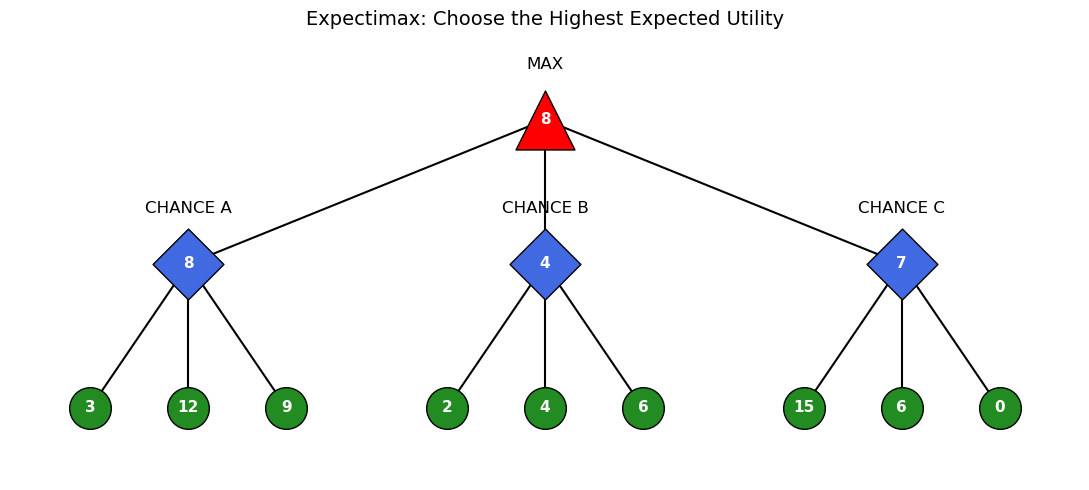

In [ ]:
import matplotlib.pyplot as plt

chance_tree = [[3, 12, 9], [2, 4, 6], [15, 6, 0]]

def expectimax(node, is_max=True):
    if not isinstance(node, list):
        return node
    values = [expectimax(child, not is_max) for child in node]
    return max(values) if is_max else sum(values) / len(values)

def draw_tree(tree, expected_values, result):
    fig, ax = plt.subplots(figsize=(11, 5))
    branch_x = [(i - (len(tree) - 1) / 2) * 4
                for i in range(len(tree))]

    def node(x, y, label, marker, color, size):
        ax.scatter(x, y, marker=marker, s=size, color=color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, str(label), ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

    # MAX: red upward triangle
    node(0, 2, f"{result:g}", "^", "red", 1800)
    ax.text(0, 2.35, "MAX", ha="center", fontsize=12)

    for i, (x, branch) in enumerate(zip(branch_x, tree)):
        ax.plot([0, x], [2, 1], color="black", zorder=1)

        # CHANCE: blue diamond
        node(x, 1, f"{expected_values[i]:g}", "D", "royalblue", 1300)
        ax.text(x, 1.35, f"CHANCE {'ABC'[i]}",
                ha="center", fontsize=12)

        probability = 1 / len(branch)

        for j, leaf in enumerate(branch):
            leaf_x = x + (j - (len(branch) - 1) / 2) * 1.1
            ax.plot([x, leaf_x], [1, 0], color="black", zorder=1)

            # Terminal: green circle
            node(leaf_x, 0, leaf, "o", "forestgreen", 900)

    ax.set_ylim(-0.5, 2.6)
    ax.set_xlim(min(branch_x) - 2, max(branch_x) + 2)
    ax.axis("off")
    ax.set_title("Expectimax: Choose the Highest Expected Utility",
                 fontsize=14)
    plt.tight_layout()
    plt.show()

expected_values = [expectimax(branch, False) for branch in chance_tree]
expected_result = expectimax(chance_tree)
best_move = expected_values.index(expected_result)

print("Expected branch values:", expected_values)
print("Expectimax value:", expected_result)
print("Best branch:", "ABC"[best_move])

draw_tree(chance_tree, expected_values, expected_result)

- **Tree structure:** The root is MAX, the middle nodes are CHANCE nodes, and the numbers are terminal utilities.
- **Recursive evaluation:** `expectimax()` alternates between MAX and CHANCE. MAX chooses the largest child value; CHANCE computes the average of its child values.
- **Outcome probabilities:** Each branch has three equally likely outcomes, so each outcome has probability $1/3$.
- **Branch A:** Its expected value is $(3+12+9)/3 = 8$.
- **Branch B:** Its expected value is $(2+4+6)/3 = 4$.
- **Branch C:** Its expected value is $(15+6+0)/3 = 7$.
- **Best move:** The MAX root chooses $\max(8,4,7)=8$, so the best branch is **A**.
- **Leaf evaluation:** All **9 terminal leaves** are evaluated during the root search. This implementation does not prune.
- **Visualization:** MAX is a red upward triangle, CHANCE nodes are blue diamonds, and terminal nodes are green circles. Each internal node displays its computed value.
- **Probability variable:** `probability` is calculated in `draw_tree()` but is not used or displayed. Equal probabilities are already implicit in the averaging operation.

**Unequal probabilities at CHANCE nodes.**

Expected branch values: [10.6, 15.0, 7.4]
Expectimax value: 15.0
Best branch: B


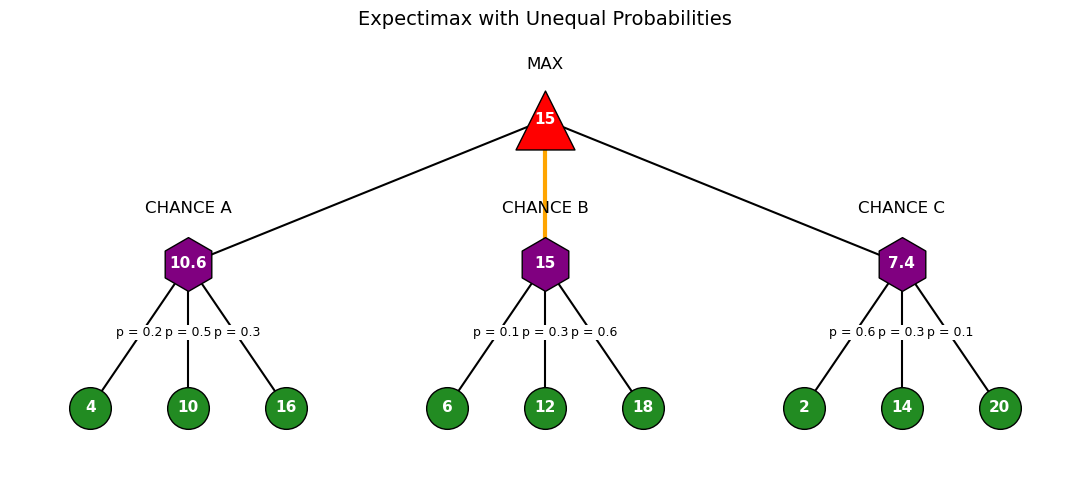

In [ ]:
import matplotlib.pyplot as plt

chance_tree = [[4, 10, 16], [6, 12, 18], [2, 14, 20]]
probabilities = [[0.2, 0.5, 0.3],
                 [0.1, 0.3, 0.6],
                 [0.6, 0.3, 0.1]]

def expectimax(tree, probabilities):
    expected_values = [
        sum(p * value for p, value in zip(probs, branch))
        for branch, probs in zip(tree, probabilities)
    ]
    result = max(expected_values)
    move = expected_values.index(result)
    return expected_values, result, move

def draw_tree(tree, probabilities, expected_values, result, move):
    fig, ax = plt.subplots(figsize=(11, 5))
    branch_x = [(i - (len(tree) - 1) / 2) * 4
                for i in range(len(tree))]

    def node(x, y, label, marker, color, size):
        ax.scatter(x, y, marker=marker, s=size, color=color,
                   edgecolors="black", zorder=3)
        ax.text(x, y, str(label), ha="center", va="center",
                color="white", weight="bold", fontsize=11, zorder=4)

    # MAX: red upward triangle
    node(0, 2, f"{result:g}", "^", "red", 1800)
    ax.text(0, 2.35, "MAX", ha="center", fontsize=12)

    for i, (x, branch) in enumerate(zip(branch_x, tree)):
        # Highlight the best action.
        ax.plot([0, x], [2, 1],
                color="orange" if i == move else "black",
                linewidth=3 if i == move else 1.5, zorder=1)

        # CHANCE: purple hexagon
        node(x, 1, f"{expected_values[i]:g}", "h", "purple", 1500)
        ax.text(x, 1.35, f"CHANCE {'ABC'[i]}",
                ha="center", fontsize=12)

        for j, leaf in enumerate(branch):
            leaf_x = x + (j - (len(branch) - 1) / 2) * 1.1
            ax.plot([x, leaf_x], [1, 0], color="black", zorder=1)

            ax.text((x + leaf_x) / 2, 0.5,
                    f"p = {probabilities[i][j]:g}",
                    ha="center", fontsize=9,
                    bbox=dict(facecolor="white", edgecolor="none", pad=1))

            # Terminal: green circle
            node(leaf_x, 0, leaf, "o", "forestgreen", 900)

    ax.set_ylim(-0.5, 2.6)
    ax.set_xlim(min(branch_x) - 2, max(branch_x) + 2)
    ax.axis("off")
    ax.set_title("Expectimax with Unequal Probabilities", fontsize=14)
    plt.tight_layout()
    plt.show()

expected_values, result, move = expectimax(chance_tree, probabilities)

print("Expected branch values:", [round(v, 2) for v in expected_values])
print("Expectimax value:", round(result, 2))
print("Best branch:", "ABC"[move])

draw_tree(chance_tree, probabilities, expected_values, result, move)

### Expectimax with Unequal Probabilities

- **Tree structure:** The root is MAX, the middle nodes are CHANCE nodes, and the numbers are terminal utilities.
- **Outcome probabilities:** Each terminal value has an assigned probability. The probabilities within each branch sum to **1**.
- **Expected values:** `expectimax()` computes each branch’s probability-weighted utility using $\sum_i p_i v_i$.
- **Branch A:** Its expected value is $0.2(4)+0.5(10)+0.3(16)=10.6$.
- **Branch B:** Its expected value is $0.1(6)+0.3(12)+0.6(18)=15$.
- **Branch C:** Its expected value is $0.6(2)+0.3(14)+0.1(20)=7.4$.
- **Best move:** MAX chooses $\max(10.6,15,7.4)=15$, so the best branch is **B**.
- **Leaf evaluation:** All **9 terminal values** contribute to the calculation. This implementation does not prune.
- **Visualization:** MAX is a red upward triangle, CHANCE nodes are purple hexagons, and terminal nodes are green circles.
- **Edge labels:** Each CHANCE-to-terminal edge displays the outcome probability.
- **Best-action highlight:** The edge from MAX to branch **B** is orange and thicker than the other edges.